# NeuroMotion — Playground

The core project uses the imagined unilateral fist runs **R04, R08, and R12**. In these runs, `T0` represents rest, `T1` represents left-fist imagery, and `T2` represents right-fist imagery. The run-aware mapping is important because `T1` and `T2` mean different movements in other runs.

## 1. Dataset provenance

- **Source:** PhysioNet EEG Motor Movement/Imagery Dataset v1.0.0
- **URL:** https://physionet.org/content/eegmmidb/1.0.0/
- **DOI:** 10.13026/C28G6P
- **Original dataset citation:** Schalk, G. (2009). *EEG Motor Movement/Imagery Dataset (version 1.0.0).* PhysioNet.
- **License:** Open Data Commons Attribution License v1.0
- **Retrieved/obtained:** 2026-10-05
- **Format:** EDF+ EEG recordings with annotations
- **Sampling rate:** 160 Hz
- **Channels:** 64 EEG channels

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mne
except ImportError as exc:
    raise ImportError(
        "MNE-Python is required. Run: pip install -r requirements.txt"
    ) from exc

print("Python environment ready.")
print("MNE version:", mne.__version__)


Python environment ready.
MNE version: 1.13.2


## 2. Configure the local dataset path

```text
data/
├── S001/
│   ├── S001R01.edf
│   ├── S001R02.edf
│   ├── ...
│   └── S001R14.edf
├── S002/
└── ...
```

In [2]:
from pathlib import Path

DATA_ROOT = Path("data")

candidate_roots = [
    DATA_ROOT,
    Path.home() / "mne_data" / "MNE-eegbci-data" / "files" / "eegmmidb" / "1.0.0",
    Path("eegmmidb"),
]

def find_edf_files(root: Path):
    return sorted(root.rglob("*.edf")) if root.exists() else []

edf_files = []
for root in candidate_roots:
    files = find_edf_files(root)
    if files:
        DATA_ROOT = root
        edf_files = files
        break

if not edf_files:
    raise FileNotFoundError(
        "No EDF files were found. Set DATA_ROOT to the folder containing S001, S002, ..."
    )

print("Dataset root:", DATA_ROOT.resolve())
print("EDF recordings found:", len(edf_files))
print("First five files:")
for f in edf_files[:5]:
    print("  ", f)


Dataset root: C:\Users\cdsch\OneDrive\Documents\AIS\NeuroMotion\data
EDF recordings found: 1526
First five files:
   data\S001\S001R01.edf
   data\S001\S001R02.edf
   data\S001\S001R03.edf
   data\S001\S001R04.edf
   data\S001\S001R05.edf


## 3. Basic dataset structure

In [3]:
# Prints a summary of the dataset contents.
# Number of subjects, number of recordings, number of EEG channels, sampling rate, and core imagery runs.
subject_ids = sorted({f.parent.name for f in edf_files if re.fullmatch(r"S\d{3}", f.parent.name)})
run_pattern = re.compile(r"S\d{3}R\d{2}\.edf$")
recording_names = [f.name for f in edf_files if run_pattern.fullmatch(f.name)]

print(f"Subjects found: {len(subject_ids)}")
print(f"EDF recordings found: {len(recording_names)}")
print(f"Subject range: {subject_ids[0]} to {subject_ids[-1]}")
if subject_ids:
    print("\nExample recordings:")
    for name in recording_names[:14]:
        print(" ", name)
else:
    print("No subject folders matched the expected pattern.")

summary = pd.DataFrame({
    "item": ["subjects", "EDF recordings", "EEG channels", "sampling rate (Hz)", "core imagery runs"],
    "value": [len(subject_ids), len(recording_names), 64, 160, "R04, R08, R12"]
})
display(summary)


Subjects found: 109
EDF recordings found: 1526
Subject range: S001 to S109

Example recordings:
  S001R01.edf
  S001R02.edf
  S001R03.edf
  S001R04.edf
  S001R05.edf
  S001R06.edf
  S001R07.edf
  S001R08.edf
  S001R09.edf
  S001R10.edf
  S001R11.edf
  S001R12.edf
  S001R13.edf
  S001R14.edf


,item,value
0,subjects,109
1,EDF recordings,1526
2,EEG channels,64
3,sampling rate (Hz),160
4,core imagery runs,"R04, R08, R12"


## 4. Load one real EEG recording

For the first inspection, I'll load `S001R04.edf`, which is an imagined left/right fist run.

In [4]:
def locate_recording(subject="S001", run="R04"):
    filename = f"{subject}{run}.edf"
    matches = list(DATA_ROOT.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename} below {DATA_ROOT.resolve()}")
    return matches[0]

example_file = locate_recording("S001", "R04")
raw = mne.io.read_raw_edf(example_file, preload=False, verbose=False)

print("File:", example_file)
print("Number of channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Duration:", round(raw.times[-1], 2), "seconds")
print("Data type:", raw.get_data().dtype)
print("First 10 channel names:", raw.ch_names[:10])


File: data\S001\S001R04.edf
Number of channels: 64
Sampling frequency: 160.0 Hz
Duration: 124.99 seconds
Data type: float64
First 10 channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']


## 5. Inspect annotations and map them to project classes

The dataset uses `T0`, `T1`, and `T2` annotations. For R04/R08/R12, the project maps them as follows:

| Dataset annotation | Project class | Meaning |
|---|---|---|
| T0 | Rest | No intended movement |
| T1 | Left Hand | Imagined left-fist movement |
| T2 | Right Hand | Imagined right-fist movement |

This mapping is intentionally restricted to the unilateral imagined runs. The same annotation codes have different meanings in other run groups.

In [5]:
print("Annotations in example recording:")
print(raw.annotations)

annotation_rows = []
for onset, duration, description in zip(
    raw.annotations.onset,
    raw.annotations.duration,
    raw.annotations.description,
):
    annotation_rows.append({
        "onset_sec": round(float(onset), 3),
        "duration_sec": round(float(duration), 3),
        "annotation": str(description),
    })

annotations_df = pd.DataFrame(annotation_rows)
display(annotations_df.head(15))

PROJECT_LABELS = {
    "T0": "Rest",
    "T1": "Left Hand",
    "T2": "Right Hand",
}

annotations_df["project_class"] = annotations_df["annotation"].map(PROJECT_LABELS)
display(annotations_df["project_class"].value_counts(dropna=False).rename_axis("class").to_frame("count"))


Annotations in example recording:
<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


,onset_sec,duration_sec,annotation
0,0.0,4.2,T0
1,4.2,4.1,T2
2,8.3,4.2,T0
3,12.5,4.1,T1
4,16.6,4.2,T0
5,20.8,4.1,T1
6,24.9,4.2,T0
7,29.1,4.1,T2
8,33.2,4.2,T0
9,37.4,4.1,T2


,count
class,
Rest,15
Left Hand,8
Right Hand,7


## 6. Display a few real EEG signals

C3, Cz, and C4 are useful channels to inspect for motor-related activity because they are located over/near sensorimotor regions. The plot below displays a short raw segment so that the signal can be visually inspected before preprocessing.

In [6]:
# Plot a 5-second EEG segment using a non-GUI Matplotlib backend.

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt

# The PhysioNet EEGMMIDB channel names include periods.
# Select the motor-related channels C3, Cz, and C4.
preferred_channels = [
    ch for ch in ["C3..", "Cz..", "C4.."]
    if ch in raw.ch_names
]

# Fall back to the first three channels if these aren't available.
if len(preferred_channels) < 3:
    preferred_channels = raw.ch_names[:3]

print("Channels being plotted:", preferred_channels)

# Extract the first 5 seconds of data.
stop = min(
    raw.n_times,
    int(raw.info["sfreq"] * 5)
)

segment, times = raw.get_data(
    picks=preferred_channels,
    start=0,
    stop=stop,
    return_times=True
)

print("Segment shape:", segment.shape)
print("Duration:", times[-1], "seconds")

# Create the plot.
fig, axes = plt.subplots(
    len(preferred_channels),
    1,
    figsize=(12, 7),
    sharex=True
)

if len(preferred_channels) == 1:
    axes = [axes]

for i, (ax, ch) in enumerate(zip(axes, preferred_channels)):
    # Convert EEG from Volts to microvolts for easier interpretation.
    ax.plot(times, segment[i] * 1e6)

    ax.set_ylabel(f"{ch}\n(µV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Example EEG Segment — S001R04")

plt.tight_layout()

# Save the figure instead of using plt.show().
output_file = "example_eeg_segment.png"
fig.savefig(output_file, dpi=150, bbox_inches="tight")

plt.close(fig)

print(f"Plot saved successfully to: {output_file}")


Channels being plotted: ['C3..', 'Cz..', 'C4..']
Segment shape: (3, 800)
Duration: 4.99375 seconds
Plot saved successfully to: example_eeg_segment.png


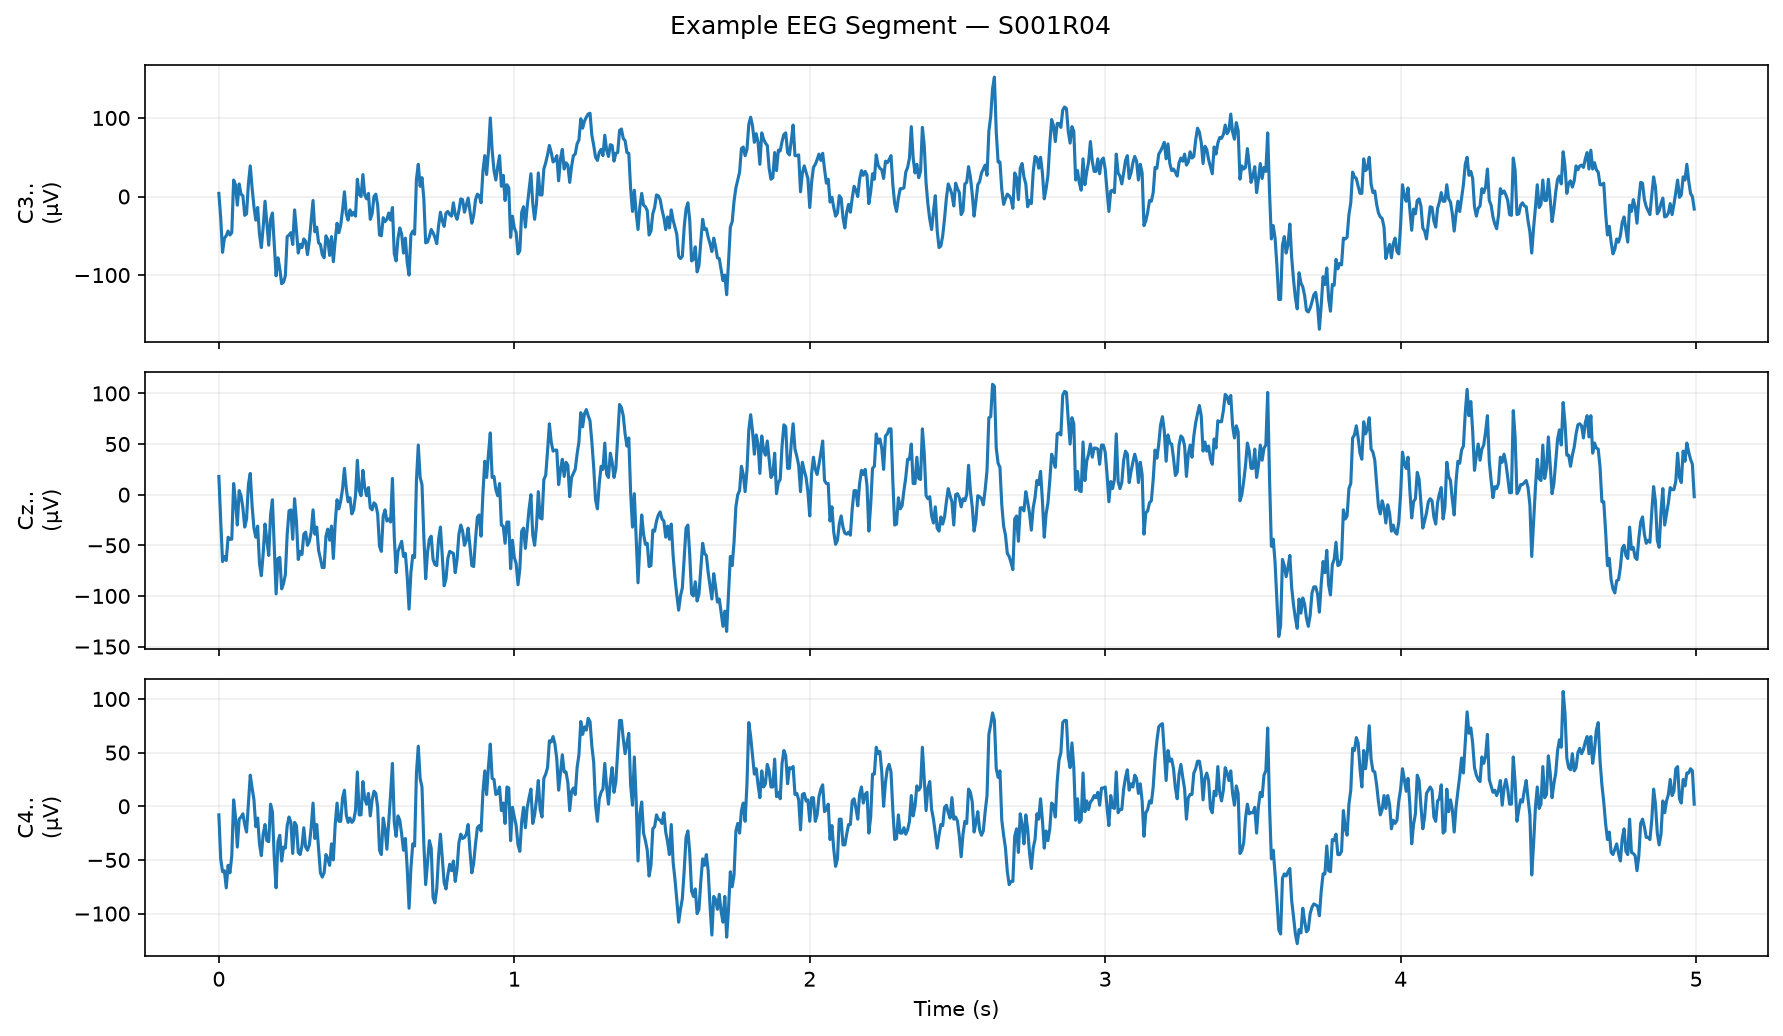

In [7]:
from IPython.display import Image
Image(output_file, width=900)

## 7. Initial data-quality checks

Checks for missing/non-finite values, unexpected sampling rates, channel-count differences, and unusually large signal values.

In [8]:
def inspect_file(path):
    r = mne.io.read_raw_edf(path, preload=True, verbose=False)
    data = r.get_data()
    return {
        "file": path.name,
        "channels": len(r.ch_names),
        "sfreq": float(r.info["sfreq"]),
        "duration_sec": float(r.times[-1]),
        "finite": bool(np.isfinite(data).all()),
        "min_uV": float(np.min(data) * 1e6),
        "max_uV": float(np.max(data) * 1e6),
    }

# Only inspect a small sample
sample_files = []
for subject in subject_ids[:3]:
    for run in ["R04", "R08", "R12"]:
        candidate = DATA_ROOT / subject / f"{subject}{run}.edf"
        if candidate.exists():
            sample_files.append(candidate)

quality_df = pd.DataFrame([inspect_file(p) for p in sample_files])
display(quality_df)

print("All sampled files finite:", quality_df["finite"].all())
print("Unique channel counts:", sorted(quality_df["channels"].unique()))
print("Unique sampling rates:", sorted(quality_df["sfreq"].unique()))


,file,channels,sfreq,duration_sec,finite,min_uV,max_uV
0,S001R04.edf,64,160.0,124.99375,True,-376.0,595.0
1,S001R08.edf,64,160.0,124.99375,True,-507.0,582.0
2,S001R12.edf,64,160.0,124.99375,True,-494.0,586.0
3,S002R04.edf,64,160.0,122.99375,True,-252.0,309.0
4,S002R08.edf,64,160.0,122.99375,True,-246.0,310.0
5,S002R12.edf,64,160.0,122.99375,True,-290.0,316.0
6,S003R04.edf,64,160.0,124.99375,True,-415.0,617.0
7,S003R08.edf,64,160.0,124.99375,True,-525.0,649.0
8,S003R12.edf,64,160.0,124.99375,True,-668.0,643.0


All sampled files finite: True
Unique channel counts: [np.int64(64)]
Unique sampling rates: [np.float64(160.0)]


## 8. Prepare the project trial definition

**Core training data:** R04, R08, R12  
**Events:** T0, T1, T2  
**Target classes:** Rest, Left Hand, Right Hand  
**Future model input:** a fixed-length EEG window sampled at 160 Hz

The exact window length and preprocessing filters will be finalized later.

In [9]:
IMAGERY_RUNS = {"R04", "R08", "R12"}
ANNOTATION_TO_CLASS = {
    "T0": "Rest",
    "T1": "Left Hand",
    "T2": "Right Hand",
}

def run_is_core_imagery(path):
    return path.stem[-3:] in IMAGERY_RUNS

core_files = [p for p in edf_files if run_is_core_imagery(p)]
print("Core imagery EDF recordings available:", len(core_files))
print("Core runs:", sorted(IMAGERY_RUNS))
print("Target mapping:", ANNOTATION_TO_CLASS)


Core imagery EDF recordings available: 327
Core runs: ['R04', 'R08', 'R12']
Target mapping: {'T0': 'Rest', 'T1': 'Left Hand', 'T2': 'Right Hand'}


## 9. What I noticed about the data

The most important data-management issue is that the annotation codes are **run-dependent**. `T1` and `T2` do not always represent the same physical action throughout the full dataset. For this project, I therefore restrict the initial dataset to R04/R08/R12, where the task is imagined unilateral fist movement and the labels can be mapped consistently to left hand, right hand, and rest.

The dataset is also high-dimensional: each recording contains 64 EEG channels sampled at 160 Hz. This means that even a short time window contains thousands of signal values, so the next stage will need careful preprocessing and feature/model selection rather than treating the raw recordings as ordinary tabular data.